# 05 - Régularisation : L1, L2, Dropout, Batch Normalization, Early Stopping

On part d'un réseau **volontairement trop gros** (3 × 256 neurones pour ~470 exemples d'entraînement)
qui sur-apprend, puis on compare les techniques de régularisation :

- **L2** (`kernel_regularizer=l2`) : pénalise les grands poids ; sensible aux valeurs extrêmes ;
- **L1** (`kernel_regularizer=l1`) : pousse les petits poids vers 0, fait de la **sélection de variables** ;
- **Dropout** : désactive aléatoirement une fraction des neurones à chaque pas d'entraînement ;
- **Batch Normalization** : normalise les activations de chaque couche, effet régularisant ;
- **Early Stopping** : arrête l'entraînement quand la perte de validation ne s'améliore plus.

Avec L1/L2, la `loss` contient aussi la pénalité : on suit donc la métrique **`mae`** pour comparer les modèles.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from velo_utils import load_splits, plot_history, PALETTE

keras.utils.set_random_seed(42)  # reproductibilité
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


In [2]:
X_train, X_test, y_train, y_test = load_splits()
Xtr, Xte = X_train.to_numpy(), X_test.to_numpy()
ytr, yte = y_train.to_numpy(), y_test.to_numpy()
n_features = Xtr.shape[1]
print("train :", Xtr.shape, "| test :", Xte.shape)

train : (585, 33) | test : (146, 33)


In [3]:
from tensorflow.keras import regularizers

def make_model(units=(256, 256, 256), reg=None, dropout=0.0, batchnorm=False):
    norm = layers.Normalization()
    norm.adapt(Xtr)
    model = keras.Sequential([keras.Input(shape=(n_features,)), norm])
    for u in units:
        # avec BatchNorm, le biais de la couche Dense est redondant
        model.add(layers.Dense(u, kernel_regularizer=reg, use_bias=not batchnorm))
        if batchnorm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        if dropout:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1))
    # learning rate plus faible qu'au notebook 02 : courbes plus lisses pour ce gros réseau
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=3e-4), loss="mae", metrics=["mae"])
    return model

EPOCHS = 300

In [4]:
configs = {
    "sans régularisation": dict(),
    "L2 (1e-3)": dict(reg=regularizers.l2(1e-3)),
    "L1 (1e-2)": dict(reg=regularizers.l1(1e-2)),
    "Dropout (0.3)": dict(dropout=0.3),
    "Batch Normalization": dict(batchnorm=True),
}

histories, models = {}, {}
for name, cfg in configs.items():
    keras.utils.set_random_seed(42)
    models[name] = make_model(**cfg)
    start = time.time()
    histories[name] = models[name].fit(Xtr, ytr, epochs=EPOCHS, batch_size=32, validation_split=0.2, verbose=0)
    print(f"{name:22s} {time.time() - start:5.1f} s")

sans régularisation     34.3 s


L2 (1e-3)               36.9 s


L1 (1e-2)               43.1 s


Dropout (0.3)           32.4 s


Batch Normalization     32.2 s


## Early Stopping

On reprend le modèle sans régularisation, mais on arrête dès que `val_loss` ne s'améliore plus pendant 50 époques,
et on restaure les meilleurs poids.

In [5]:
keras.utils.set_random_seed(42)
models["Early Stopping"] = make_model()
early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=50, restore_best_weights=True)
histories["Early Stopping"] = models["Early Stopping"].fit(
    Xtr, ytr, epochs=EPOCHS, batch_size=32, validation_split=0.2, callbacks=[early], verbose=0)
print("Arrêt à l'époque", len(histories["Early Stopping"].history["loss"]))

Arrêt à l'époque 119


## Comparaison

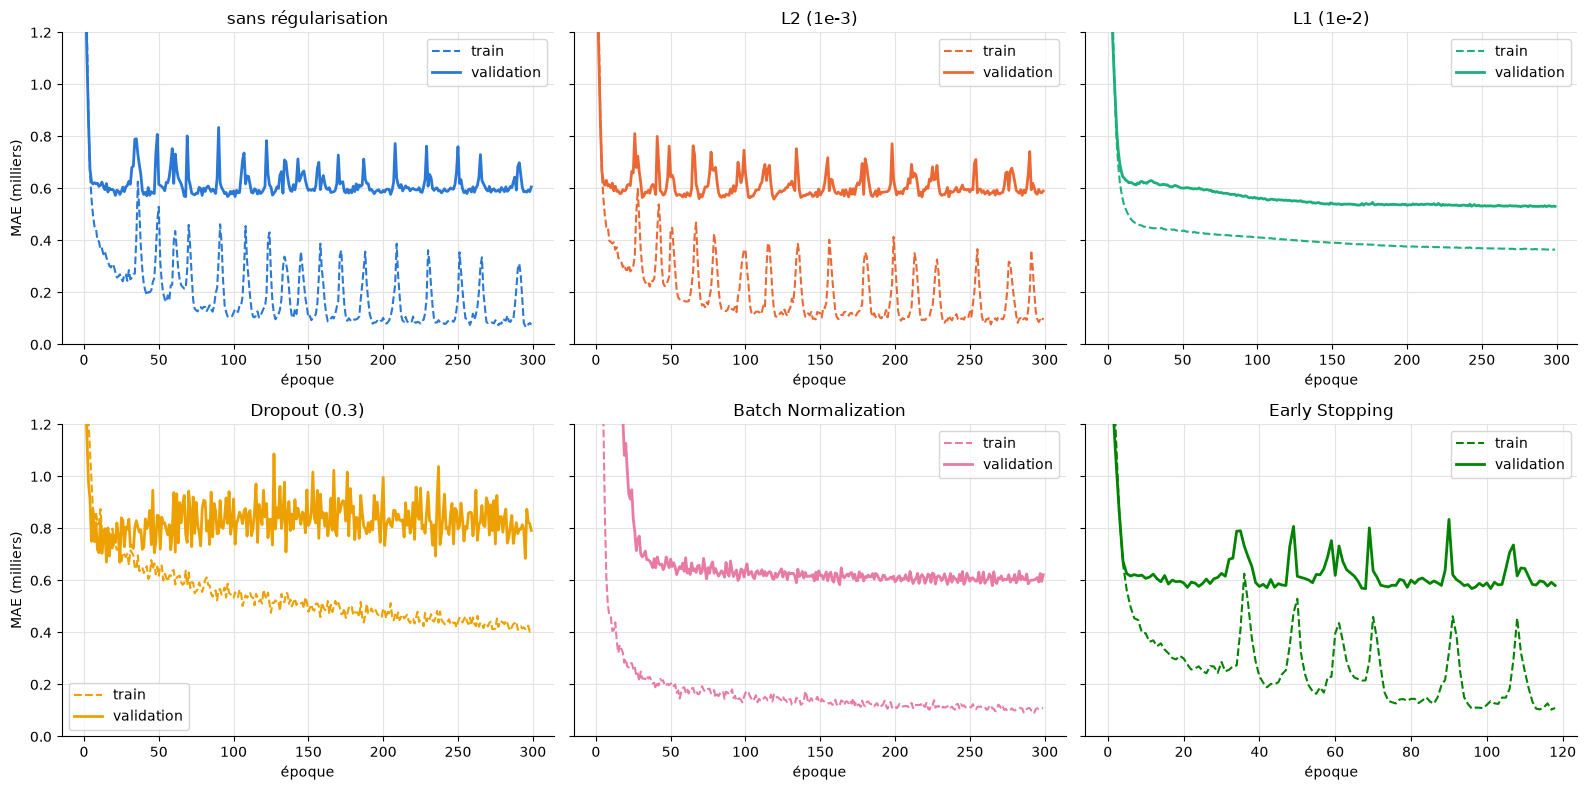

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
for i, (ax, (name, h)) in enumerate(zip(axes.flat, histories.items())):
    ax.plot(h.history["mae"], ls="--", lw=1.5, color=PALETTE[i], label="train")
    ax.plot(h.history["val_mae"], color=PALETTE[i], label="validation")
    ax.set(title=name, xlabel="époque", ylim=(0, 1.2))
    ax.legend()
for ax in axes[:, 0]:
    ax.set_ylabel("MAE (milliers)")
plt.tight_layout()
plt.show()

In [7]:
rows = []
for name, h in histories.items():
    train_mae = np.mean(h.history["mae"][-10:])  # moyenne des 10 dernières époques (moins bruité)
    val_mae = np.mean(h.history["val_mae"][-10:])
    rows.append({
        "modèle": name,
        "MAE train": train_mae,
        "MAE val": val_mae,
        "écart val - train": val_mae - train_mae,
        "meilleure MAE val": min(h.history["val_mae"]),
        "MAE test": models[name].evaluate(Xte, yte, verbose=0)[1],
    })
pd.DataFrame(rows).set_index("modèle").round(3).sort_values("MAE test")

,MAE train,MAE val,écart val - train,meilleure MAE val,MAE test
modèle,,,,,
L1 (1e-2),0.365,0.532,0.166,0.530,0.474
Early Stopping,0.156,0.602,0.446,0.568,0.544
L2 (1e-3),0.166,0.607,0.441,0.559,0.547
sans régularisation,0.151,0.619,0.468,0.568,0.552
Batch Normalization,0.105,0.606,0.501,0.580,0.606
Dropout (0.3),0.416,0.798,0.382,0.670,0.735


L'**écart val - train** mesure le sur-apprentissage : plus il est petit, moins le modèle a mémorisé le train.

À lire avec prudence :

- avec seulement ~470 jours d'entraînement et ~120 de validation, les écarts entre méthodes sont de quelques
  dizaines de locations et **changent avec la graine** : relancez avec une autre valeur de `set_random_seed` pour le vérifier ;
- une régularisation trop forte (ou mal adaptée) peut **dégrader** la performance : c'est un hyperparamètre à régler
  sur la validation, jamais sur le test ;
- pour Dropout, la MAE de train est calculée *avec* les neurones désactivés, elle est donc surestimée ;
- pour Early Stopping, les colonnes « train » et « val » correspondent aux dernières époques avant l'arrêt,
  alors que le modèle évalué sur le test a récupéré les **meilleurs** poids.

## L1 et sélection de variables

Pour chaque variable d'entrée, on somme la valeur absolue de ses poids vers la première couche cachée.
Avec L1, beaucoup de poids sont poussés vers 0 : seules les variables utiles gardent un poids important.

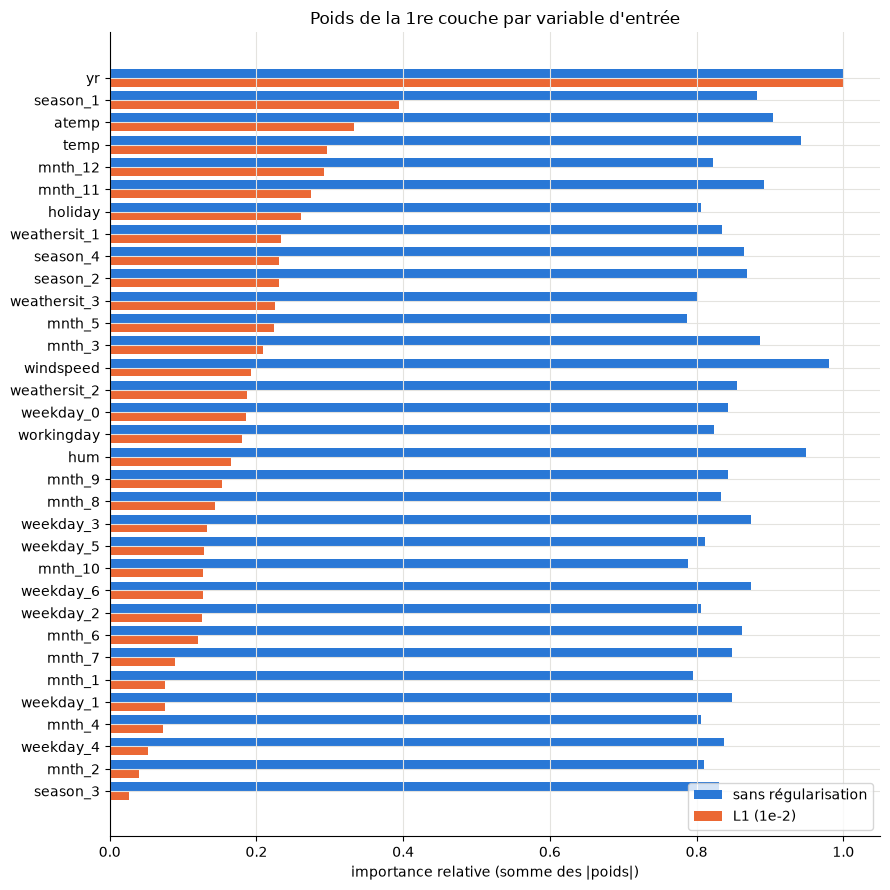

In [8]:
def input_importance(model):
    dense = next(l for l in model.layers if isinstance(l, layers.Dense))
    return np.abs(dense.kernel.numpy()).sum(axis=1)

imp = pd.DataFrame({
    "sans régularisation": input_importance(models["sans régularisation"]),
    "L1 (1e-2)": input_importance(models["L1 (1e-2)"]),
}, index=X_train.columns)
imp = imp / imp.max()  # normalisé pour comparer les deux modèles
imp = imp.sort_values("L1 (1e-2)")

fig, ax = plt.subplots(figsize=(9, 9))
y = np.arange(len(imp))
ax.barh(y + 0.2, imp["sans régularisation"], height=0.4, label="sans régularisation", color=PALETTE[0])
ax.barh(y - 0.2, imp["L1 (1e-2)"], height=0.4, label="L1 (1e-2)", color=PALETTE[1])
ax.set_yticks(y, imp.index)
ax.set(xlabel="importance relative (somme des |poids|)", title="Poids de la 1re couche par variable d'entrée")
ax.legend()
plt.tight_layout()
plt.show()

## Combiner les techniques

En pratique on combine souvent plusieurs régularisations. Exemple : L2 + Dropout + Early Stopping.

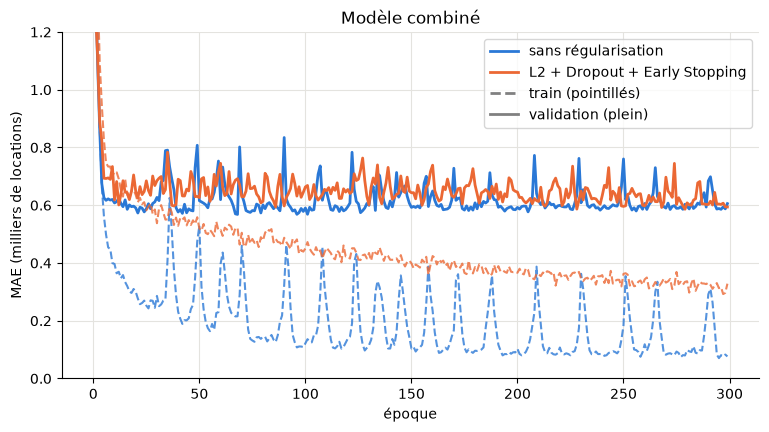

MAE test combinée : 0.511 milliers de locations


In [9]:
keras.utils.set_random_seed(42)
combo = make_model(reg=regularizers.l2(1e-3), dropout=0.2)
h_combo = combo.fit(Xtr, ytr, epochs=EPOCHS, batch_size=32, validation_split=0.2,
                    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=50, restore_best_weights=True)],
                    verbose=0)
plot_history({"sans régularisation": histories["sans régularisation"], "L2 + Dropout + Early Stopping": h_combo},
             metric="mae", title="Modèle combiné", ylim=(0, 1.2))
plt.show()
print("MAE test combinée :", round(combo.evaluate(Xte, yte, verbose=0)[1], 3), "milliers de locations")

## À vous de jouer

- Faites varier le coefficient L2 (1e-5, 1e-4, 1e-2) et le taux de Dropout (0.1, 0.5).
- Placez la `BatchNormalization` après l'activation au lieu d'avant : y a-t-il une différence ?
- Réduisez le réseau (2 × 32) : a-t-il encore besoin de régularisation ?
- Changez `patience` de l'Early Stopping (5, 50).